# Week 2 — Time-series manipulation and localized noise
    **Donovan Marshall · DEV.BAFAD290.01**

    Source: [Week 2 exercise](https://uncfsu.instructure.com/courses/53036/files/10607985?wrap=1).
    Execution uses the course-approved local option on CPU. A fixed seed makes the
    baseline and numerical comparisons reproducible.

    The assignment's parameter is named `variance`, but NumPy treats its second
    positional argument as **standard deviation**. The required API is preserved.
    See [NumPy documentation](https://numpy.org/doc/stable/reference/random/generated/numpy.random.normal.html).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
print(f'NumPy version: {np.__version__}')
print('Imports successful.')


NumPy version: 1.26.4
Imports successful.


## Baseline sensor stream


In [2]:
def generate_sensor_stream(samples=1000, features=3, seed=42):
    """Generate the course baseline: (time steps, sensor channels)."""
    np.random.seed(seed)
    t = np.linspace(0, 50, samples)
    stream = np.zeros((samples, features))
    for f in range(features):
        stream[:, f] = np.sin(t * (f + 1)) + np.random.normal(0, 0.05, samples)
    return stream

clean_stream = generate_sensor_stream(samples=1000, features=3)
print(f'Clean stream shape: {clean_stream.shape}')
print(f'Value range: [{clean_stream.min():.3f}, {clean_stream.max():.3f}]')
assert clean_stream.shape == (1000, 3)
print('Shape assertion passed.')


Clean stream shape: (1000, 3)
Value range: [-1.126, 1.157]
Shape assertion passed.


## Windowed noise injection
Copy the array, then modify only the requested half-open row interval.


In [3]:
def inject_tactical_jamming(raw_data, start_idx=400, end_idx=550, variance=2.5):
    """Return a copy with Gaussian noise in [start_idx, end_idx).

    The course's variance parameter is the Gaussian standard deviation.
    """
    poisoned_data = raw_data.copy()
    noise = np.random.normal(
        0, variance, size=(end_idx - start_idx, poisoned_data.shape[1])
    )
    poisoned_data[start_idx:end_idx, :] += noise
    return poisoned_data

original = clean_stream.copy()
jammed_stream = inject_tactical_jamming(
    clean_stream, start_idx=400, end_idx=550, variance=2.5
)
assert jammed_stream.shape == clean_stream.shape
assert not np.array_equal(jammed_stream[400:550], clean_stream[400:550])
assert np.array_equal(jammed_stream[:400], clean_stream[:400])
assert np.array_equal(jammed_stream[550:], clean_stream[550:])
assert np.array_equal(clean_stream, original), 'Input must remain unchanged'
clean_mag = np.abs(clean_stream[400:550]).mean()
jammed_mag = np.abs(jammed_stream[400:550]).mean()
print(f'Clean window mean |value|: {clean_mag:.4f}')
print(f'Jammed window mean |value|: {jammed_mag:.4f}')
assert jammed_mag > clean_mag
print('All required assertions passed; original input is unchanged.')

# Check a different feature count and window length to exclude hardcoding.
probe = np.ones((19, 5))
changed = inject_tactical_jamming(probe, start_idx=3, end_idx=8, variance=1.0)
assert changed.shape == (19, 5)
assert np.array_equal(changed[:3], probe[:3])
assert np.array_equal(changed[8:], probe[8:])
assert np.array_equal(probe, np.ones((19, 5)))
print('Parameterized shape/window check passed.')


Clean window mean |value|: 0.6470
Jammed window mean |value|: 2.1654
All required assertions passed; original input is unchanged.
Parameterized shape/window check passed.


## Clean and altered Sensor 1
The shaded interval is rows 400–549; both panels show the same channel.


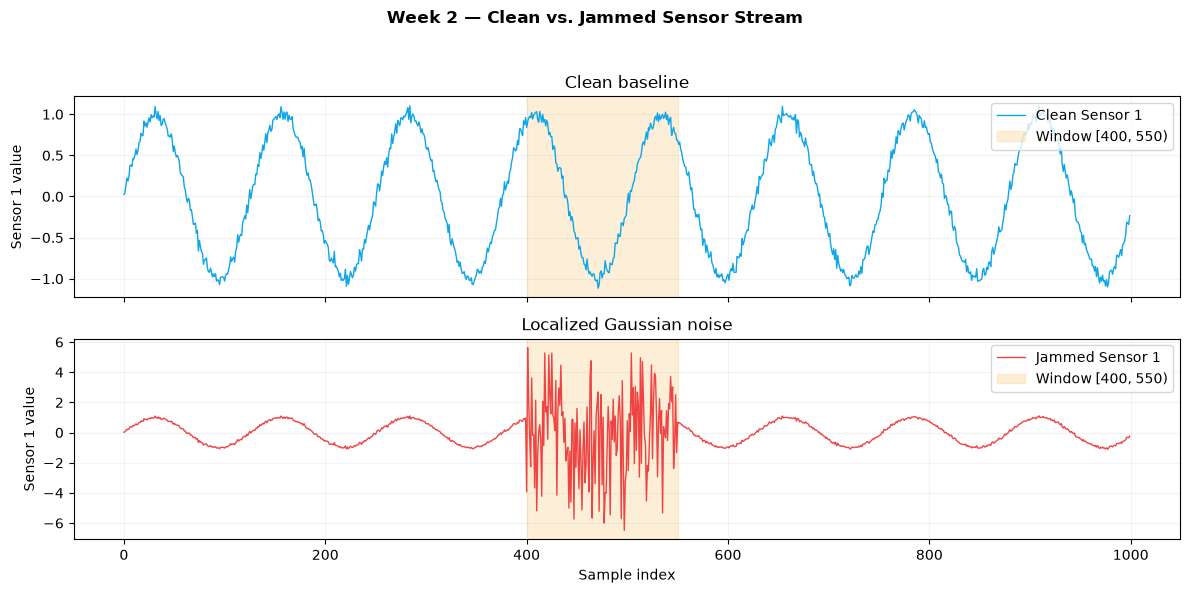

Plot saved: week02_exercise1_plot.png


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
t = np.arange(clean_stream.shape[0])
for ax, values, color, label, title in [
    (axes[0], clean_stream[:, 0], '#0EA5E9', 'Clean Sensor 1', 'Clean baseline'),
    (axes[1], jammed_stream[:, 0], '#EF4444', 'Jammed Sensor 1', 'Localized Gaussian noise')
]:
    ax.plot(t, values, color=color, linewidth=1.0, label=label)
    ax.axvspan(400, 550, color='#F59E0B', alpha=0.16, label='Window [400, 550)')
    ax.set_ylabel('Sensor 1 value')
    ax.set_title(title)
    ax.legend(loc='upper right')
    ax.grid(alpha=0.15)
axes[-1].set_xlabel('Sample index')
fig.suptitle('Week 2 — Clean vs. Jammed Sensor Stream', fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig('week02_exercise1_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved: week02_exercise1_plot.png')


## Interpretation
    ### Q1 — Visual and numerical change
    The smooth oscillation becomes much more irregular in rows 400–549, with large
    spikes around the original signal. The clean and altered window mean absolute
    magnitudes printed above are **0.6470** and
    **2.1654**, respectively. Samples outside this interval are
    unchanged, so the visible difference is localized.

    ### Q2 — Why copy the input?
    Modifying `raw_data` directly would overwrite the clean baseline shared with
    later steps. That would make clean-versus-altered comparisons unreliable and
    could contaminate a normal-data training or calibration set. A copy keeps the
    original available and lets separate experiments start from the same data.

    ### Q3 — Increasing the noise scale
    With a fixed model trained on clean data, increasing the standard deviation
    from 2.5 to 10.0 generally produces larger deviations and larger reconstruction
    errors, making those injected events easier to distinguish. Thresholds should
    still be calibrated using appropriate validation data rather than assumed
    from the injection setting. Calibration on only these extreme events could
    miss smaller anomalies or fail to control false alarms on real data.
